<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

**Worker: [vgi-x509](https://github.com/Query-farm/vgi-x509)**

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Query-farm/vgi-x509/blob/main/notebooks/01_plan_certificate_work.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/Query-farm/vgi-x509/blob/main/notebooks/README.md)


# 01 · Plan certificate work without losing the denominator

**How many certificate assignments fall inside a planning window, and how many
distinct certificates do they represent?** We will parse six synthetic X.509
certificates through the real worker and join them to eight authored inventory
assignments. Two assignments share one certificate; one has no certificate on file.

The assessment time is fixed at **2026-01-01 00:00:00 UTC**. Expired, not-yet-valid,
missing and currently in-window certificates remain separate. The experiment widens
the planning horizon without changing the certificates or assessment time.

This is an offline inventory demonstration. The fixtures are self-signed test
certificates, not production credentials. Parsing dates and names does not establish
trust, verify a hostname, check revocation, or prove what a live endpoint serves.

## Choose a planning horizon

`HORIZON_DAYS=14` includes currently time-valid certificates whose expiry is at or
before the inclusive fourteen-day boundary. The experiment changes this to 60.
The parameter accepts an integer from 1 to 365. Restart the kernel and run all after
editing it. The fixed assessment timestamp appears in the SQL below.

In [1]:
HORIZON_DAYS = 14

In [2]:
import importlib.metadata as packages
import sys

installed = {d.metadata["Name"]: d.version for d in packages.distributions()}
if installed.get("vgi-example-notebooks") != "0.3.7":
    %pip install -q "git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.7"
    if "vgi_notebooks" in sys.modules:
        raise RuntimeError("Restart the kernel, then run all cells.")

In [3]:
import haybarn
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from IPython.display import display
from vgi_notebooks import check_runtime, connect, prepare
from vgi_notebooks.presentation import finish, prose, theme

check_runtime()
if type(HORIZON_DAYS) is not int or not 1 <= HORIZON_DAYS <= 365:
    raise ValueError("HORIZON_DAYS must be an integer from 1 to 365.")
prepare("x509")
theme()
SOURCE = "Source: six synthetic Ed25519 certificates · VGI X.509 v0.4.0 · fixed 2026-01-01 UTC assessment"
session = connect(globals())

## Attach the pinned native release

The visible `github-auto` location downloads and verifies the platform's v0.4.0
release, then caches it. Running this notebook needs no Go compiler or local worker
build. It reads committed PEM/DER fixture files and makes no TLS endpoint connections.

The shared bootstrap verifies all twelve PEM/DER fixture files by SHA-256 and fetches missing companions from a pinned public commit. The connection starts with an empty temporary SQL-secret directory and persistent secrets disabled. Colab installs only the shared base package; the local locked environment adds its `[runner]` extra.

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'x509' (TYPE vgi,LOCATION 'github-auto://Query-farm/vgi-x509@v0.4.0');

,Success


## Parse certificates once and retain their UTC timestamps

Each PEM file contains exactly one certificate. The worker accepts PEM text or DER
bytes; the SHA-256 fingerprint identifies the complete DER certificate. A serial
number is retained as text because real serials can exceed 64 bits.

`cert_not_before` and `cert_not_after` return plain TIMESTAMP values representing
UTC wall-clock time. We compare them with an explicitly UTC assessment timestamp,
without interpreting them in the machine's local timezone. The worker's
`cert_is_expired` consults the current clock and also flags not-yet-valid certificates;
we use the separate boundaries for this reproducible historical assessment.

In [5]:
%%sql
CREATE TABLE assessment AS
SELECT TIMESTAMP '2026-01-01 00:00:00' AS as_of_utc,
 TIMESTAMP '2026-01-01 00:00:00'+{{ HORIZON_DAYS }}*INTERVAL '1 day' AS horizon_utc;
CREATE TABLE certificate_files AS
SELECT regexp_extract(filename,'([^/]+)\.pem$',1) AS certificate_id,content AS pem
FROM read_text('fixtures/*.pem');
CREATE TABLE parsed_certificates AS
SELECT certificate_id,x509.main.cert_fingerprint(pem) AS fingerprint,
 x509.main.cert_serial(pem) AS serial,x509.main.cert_subject(pem) AS subject,
 x509.main.cert_issuer(pem) AS issuer,x509.main.cert_not_before(pem) AS not_before_utc,
 x509.main.cert_not_after(pem) AS not_after_utc,x509.main.cert_sans(pem) AS sans,
 x509.main.cert_is_ca(pem) AS is_ca,x509.main.cert_key_algorithm(pem) AS key_algorithm
FROM certificate_files;
SELECT certificate_id,serial,not_before_utc,not_after_utc,key_algorithm,is_ca,sans
FROM parsed_certificates ORDER BY not_after_utc;

,certificate_id,serial,not_before_utc,not_after_utc,key_algorithm,is_ca,sans
0,expired,1001,2025-11-02,2025-12-22,Ed25519,False,[expired.example]
1,shared-soon,1002,2025-12-02,2026-01-08,Ed25519,False,[shared-soon.example]
2,boundary,1003,2025-12-02,2026-01-15,Ed25519,False,[boundary.example]
3,later,1004,2025-12-02,2026-02-15,Ed25519,False,[later.example]
4,future,1005,2026-01-11,2026-04-01,Ed25519,False,[future.example]
5,long,1006,2025-12-02,2026-05-01,Ed25519,False,[long.example]


## What kind of certificate work does this inventory represent?

Before applying dates, inspect the parsed CA flag, public-key algorithm and subject-alternative names (SANs). A CA certificate would require a different discussion from this example's leaf-certificate renewal list; the public-key algorithm tells an implementer which key type this inventory currently uses. SANs preserve the requested name scope when two assignments share one certificate.

This is a description of the supplied material, not an algorithm recommendation or a hostname check. Keep every certificate in the denominator even if its profile differs. A listed SAN does not establish that an assignment's endpoint is authorized to use that name.

In [6]:
%%sql profile <<
SELECT key_algorithm,is_ca,count(*) AS certificates,
 count(*) FILTER (WHERE len(sans)>0) AS certificates_with_sans,
 sum(len(sans)) AS listed_san_entries
FROM parsed_certificates GROUP BY key_algorithm,is_ca ORDER BY key_algorithm,is_ca;

In [7]:
display(profile)
leaf_count = int(profile.loc[~profile.is_ca, "certificates"].sum())
prose(
    f"**{leaf_count} of {int(profile.certificates.sum())} observed certificates are leaves** "
    f"and the returned public-key algorithm is **{', '.join(profile.key_algorithm)}**. "
    f"**{int(profile.certificates_with_sans.sum())} certificates contain SANs**, with "
    f"**{int(profile.listed_san_entries.sum())} listed name entries** in total. "
    "This fixture inventory therefore describes leaf-certificate work with a uniform key type. "
    "The work list below retains each selected certificate's SANs and key type so its name scope "
    "survives fingerprint deduplication. The missing assignment has no parsed profile."
)

,key_algorithm,is_ca,certificates,certificates_with_sans,listed_san_entries
0,Ed25519,False,6,6,6.0


**6 of 6 observed certificates are leaves** and the returned public-key algorithm is **Ed25519**. **6 certificates contain SANs**, with **6 listed name entries** in total. This fixture inventory therefore describes leaf-certificate work with a uniform key type. The work list below retains each selected certificate's SANs and key type so its name scope survives fingerprint deduplication. The missing assignment has no parsed profile.

## Reconcile PEM and DER representations

The PEM armor is a text representation of the DER bytes. Matching fingerprints
demonstrate that each supplied PEM/DER pair contains the same certificate. We also
compare the worker's fingerprint with SQL's SHA-256 of the original DER bytes.
This identifies certificate bytes; it does not validate the signature or trust chain.

All fixture subjects equal their issuers. That is evidence of being **self-issued**;
subject/issuer equality alone is not a signature check. The generation script tells
us these particular test fixtures were also signed with their own keys.

In [8]:
%%sql
CREATE TABLE der_audit AS
SELECT regexp_extract(filename,'([^/]+)\.der$',1) AS certificate_id,
 x509.main.cert_fingerprint(content) AS der_fingerprint,sha256(content) AS bytes_sha256
FROM read_blob('fixtures/*.der');
SELECT p.certificate_id,p.fingerprint=d.der_fingerprint AS pem_matches_der,
 d.der_fingerprint=d.bytes_sha256 AS matches_original_der_hash,
 p.subject=p.issuer AS self_issued
FROM parsed_certificates p JOIN der_audit d USING(certificate_id) ORDER BY certificate_id;

,certificate_id,pem_matches_der,matches_original_der_hash,self_issued
0,boundary,True,True,True
1,expired,True,True,True
2,future,True,True,True
3,later,True,True,True
4,long,True,True,True
5,shared-soon,True,True,True


## Join the complete inventory before classifying it

The assignments are authored records, not results from a live scan. `api-primary`
and `api-standby` intentionally reference the same certificate. `uncollected` has no
certificate on file, and remains in the left-joined inventory with NULL parsed fields.
No absent certificate is treated as expired, valid or an empty fingerprint.

We split the time-window states before applying the planning horizon. The fixture
named `boundary` expires exactly at the fourteen-day boundary and is included.
The future certificate remains not yet valid even when its eventual expiry is
within a wider requested planning window.

In [9]:
%%sql
CREATE TABLE assignments AS
SELECT * FROM (VALUES
 ('retired-api','expired'),('api-primary','shared-soon'),('api-standby','shared-soon'),
 ('boundary-service','boundary'),('batch-service','later'),
 ('staged-service','future'),('long-lived-service','long'),('uncollected',NULL)
) t(assignment_id,certificate_id);
CREATE TABLE certificate_states AS
SELECT p.*,a.*,CASE
 WHEN a.as_of_utc<p.not_before_utc THEN 'Not yet valid at assessment'
 WHEN a.as_of_utc>p.not_after_utc THEN 'Expired at assessment'
 WHEN p.not_after_utc<=a.horizon_utc THEN 'Expires within planning window'
 ELSE 'Expires beyond planning window' END AS time_state,
 date_diff('second',a.as_of_utc,p.not_before_utc)/86400.0 AS starts_in_days,
 date_diff('second',a.as_of_utc,p.not_after_utc)/86400.0 AS expires_in_days
FROM parsed_certificates p CROSS JOIN assessment a;
CREATE TABLE inventory AS
SELECT a.*,s.* EXCLUDE(certificate_id),
 coalesce(s.time_state,'No certificate on file') AS inventory_state
FROM assignments a LEFT JOIN certificate_states s USING(certificate_id);
SELECT assignment_id,certificate_id,expires_in_days,inventory_state FROM inventory ORDER BY assignment_id;

,assignment_id,certificate_id,expires_in_days,inventory_state
0,api-primary,shared-soon,7.0,Expires within planning window
1,api-standby,shared-soon,7.0,Expires within planning window
2,batch-service,later,45.0,Expires beyond planning window
3,boundary-service,boundary,14.0,Expires within planning window
4,long-lived-service,long,120.0,Expires beyond planning window
5,retired-api,expired,-10.0,Expired at assessment
6,staged-service,future,90.0,Not yet valid at assessment
7,uncollected,None,NaN,No certificate on file


In [10]:
%%sql timeline <<
SELECT certificate_id,starts_in_days,expires_in_days,time_state FROM certificate_states
ORDER BY expires_in_days;

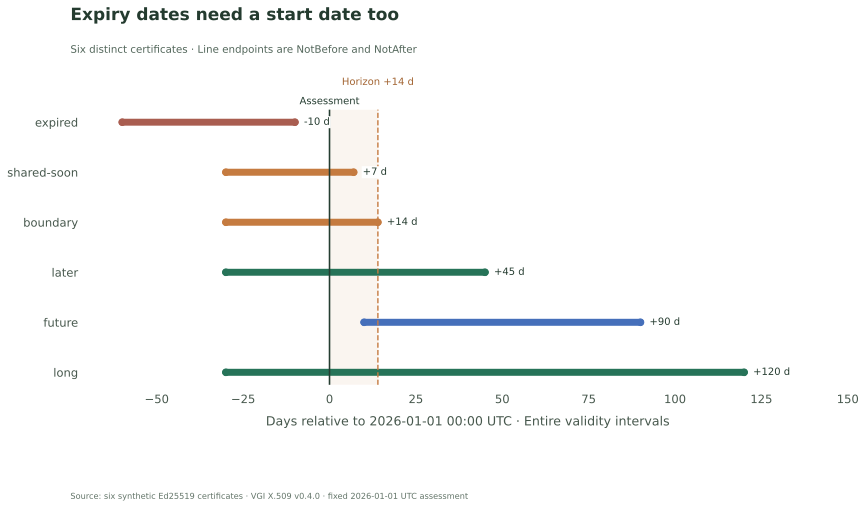

The parsed inventory has **6 distinct certificates**. The future certificate's validity interval begins after the assessment line, so it is separate from renewal planning. The expired interval ends before assessment. The timeline describes date windows, not trust status.

In [11]:
palette = {
    "Expired at assessment": "#a95d50",
    "Not yet valid at assessment": "#456fba",
    "Expires within planning window": "#c57b40",
    "Expires beyond planning window": "#267358",
    "No certificate on file": "#8a9790",
}
fig, ax = plt.subplots(figsize=(12, 7.5))
for y, row in enumerate(timeline.itertuples()):
    ax.plot(
        [row.starts_in_days, row.expires_in_days],
        [y, y],
        color=palette[row.time_state],
        linewidth=7,
        solid_capstyle="round",
    )
    ax.scatter(
        [row.starts_in_days, row.expires_in_days],
        [y, y],
        color=palette[row.time_state],
        s=45,
        zorder=3,
    )
    ax.annotate(
        f"{row.expires_in_days:+.0f} d",
        (row.expires_in_days, y),
        xytext=(9, 0),
        textcoords="offset points",
        va="center",
        fontsize=10,
        bbox={"facecolor": "white", "edgecolor": "none", "pad": 1},
    )
ax.axvspan(0, HORIZON_DAYS, color="#c57b40", alpha=0.08)
ax.axvline(0, color="#253d31", linewidth=1.6)
ax.axvline(HORIZON_DAYS, color="#c57b40", linestyle="--", linewidth=1.4)
ax.text(
    0,
    1.02,
    "Assessment",
    transform=ax.get_xaxis_transform(),
    ha="center",
    fontsize=10,
    color="#253d31",
)
ax.text(
    HORIZON_DAYS,
    1.09,
    f"Horizon +{HORIZON_DAYS} d",
    transform=ax.get_xaxis_transform(),
    ha="center",
    fontsize=10,
    color="#a26432",
)
ax.set_yticks(range(len(timeline)), timeline.certificate_id)
ax.invert_yaxis()
ax.set_xlim(
    float(timeline.starts_in_days.min()) - 10,
    max(float(timeline.expires_in_days.max()), HORIZON_DAYS) + 30,
)
ax.set_xlabel("Days relative to 2026-01-01 00:00 UTC · Entire validity intervals")
ax.grid(axis="y", visible=False)
finish(
    fig,
    "Expiry dates need a start date too",
    "Six distinct certificates · Line endpoints are NotBefore and NotAfter",
    SOURCE,
    name=f"validity-horizon-{HORIZON_DAYS}",
)
prose(
    f"The parsed inventory has **{len(timeline)} distinct certificates**. "
    "The future certificate's validity interval begins after the assessment line, so it is separate from renewal planning. "
    "The expired interval ends before assessment. The timeline describes date windows, not trust status."
)

## Count assignments and distinct certificates separately

One certificate can serve multiple inventory assignments. Use distinct fingerprints
to count certificates, and assignment rows to count affected inventory entries.
The missing-certificate bucket has one assignment and zero observed fingerprints;
zero observed certificates does not mean the assignment has no certificate in reality.

The SHA-256 grouping uses actual certificate bytes, not subject names, serials alone,
or SAN text. A renewed certificate normally has different DER and a different fingerprint.

In [12]:
%%sql counts <<
WITH states(state,sort_order) AS (VALUES
 ('Expired at assessment',1),('Expires within planning window',2),
 ('Expires beyond planning window',3),('Not yet valid at assessment',4),('No certificate on file',5))
SELECT state,count(assignment_id) AS assignments,count(DISTINCT fingerprint) AS distinct_certificates
FROM states LEFT JOIN inventory ON state=inventory_state
GROUP BY state,sort_order ORDER BY sort_order;

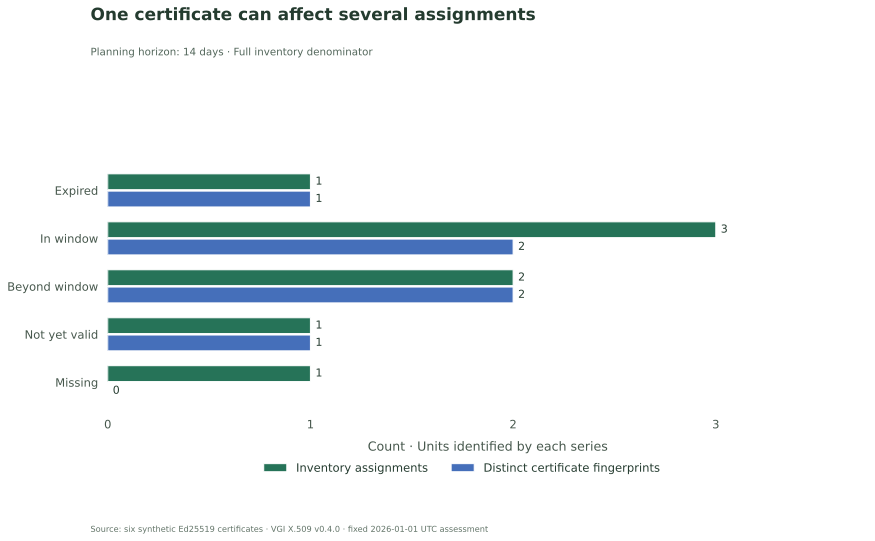

The planning window includes **3 of 8 assignments**, representing **2 distinct certificates**. The shared certificate accounts for the difference. Expired, future and missing inputs stay visible outside that selected list.

,state,assignments,distinct_certificates
0,Expired at assessment,1,1
1,Expires within planning window,3,2
2,Expires beyond planning window,2,2
3,Not yet valid at assessment,1,1
4,No certificate on file,1,0


In [13]:
y = np.arange(len(counts))
fig, ax = plt.subplots(figsize=(12, 8))
first = ax.barh(
    y - 0.18,
    counts.assignments,
    height=0.33,
    color="#267358",
    label="Inventory assignments",
)
second = ax.barh(
    y + 0.18,
    counts.distinct_certificates,
    height=0.33,
    color="#456fba",
    label="Distinct certificate fingerprints",
)
ax.bar_label(first, padding=5, fontsize=11)
ax.bar_label(second, padding=5, fontsize=11)
ax.set_yticks(y, ["Expired", "In window", "Beyond window", "Not yet valid", "Missing"])
ax.invert_yaxis()
ax.set_xlim(0, max(1, int(counts.assignments.max())) * 1.25)
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.set_xlabel("Count · Units identified by each series")
ax.grid(axis="y", visible=False)
fig.legend(loc="lower center", bbox_to_anchor=(0.5, 0.14), ncol=2, frameon=False)
finish(
    fig,
    "One certificate can affect several assignments",
    f"Planning horizon: {HORIZON_DAYS} days · Full inventory denominator",
    SOURCE,
    name=f"assignment-counts-horizon-{HORIZON_DAYS}",
)
due = counts.loc[counts.state == "Expires within planning window"].iloc[0]
prose(
    f"The planning window includes **{int(due.assignments)} of {int(counts.assignments.sum())} assignments**, "
    f"representing **{int(due.distinct_certificates)} distinct certificates**. "
    "The shared certificate accounts for the difference. Expired, future and missing inputs stay visible outside that selected list."
)
display(counts)

## Produce a certificate-level work list

Group included assignments by fingerprint so a shared certificate is not mistaken
for independent renewal work. Keep the assignment list next to the certificate.
This is an inventory planning aid: actual deployment steps and trust requirements
depend on the system. The notebook does not contact or modify any service.

Retain the parsed SAN list and key algorithm as explicit handoff context. These identify the certificate names and key type to account for in planning; they do not validate service name matching or require keeping the same key on renewal. The profile summary established that all observed inputs here are leaves, so this example does not model CA rotation.

In [14]:
%%sql
SELECT fingerprint,first(certificate_id) AS fixture_certificate,
 first(not_after_utc) AS not_after_utc,first(sans) AS certificate_sans,
 first(key_algorithm) AS public_key_algorithm,list(assignment_id ORDER BY assignment_id) AS assignments,
 count(*) AS assignment_count
FROM inventory WHERE inventory_state='Expires within planning window'
GROUP BY fingerprint ORDER BY not_after_utc,fingerprint;

,fingerprint,fixture_certificate,not_after_utc,certificate_sans,public_key_algorithm,assignments,assignment_count
0,f04bc8196741c4b94a0a1e08395724f4659eebb5ffc266...,shared-soon,2026-01-08,[shared-soon.example],Ed25519,"[api-primary, api-standby]",2
1,c18d184251c345d4273f00757db5e6f47b51b281e3d07a...,boundary,2026-01-15,[boundary.example],Ed25519,[boundary-service],1


## Verify bytes, boundaries and population accounting

These checks verify the fixture and our SQL accounting. They do not verify certificate
trust. Malformed certificates cause parsing errors rather than NULL results; a separate
malformed-input probe below checks that behavior without mixing it into the inventory.
SQL NULL input is tested independently and remains NULL.

In [15]:
%%sql checks <<
SELECT 'Six authored certificates are parsed' AS check_name,(SELECT count(*)=6 FROM parsed_certificates) AS passed
UNION ALL SELECT 'PEM and DER fingerprints agree with original bytes',
 (SELECT count(*)=6 AND bool_and(p.fingerprint=d.der_fingerprint AND d.der_fingerprint=d.bytes_sha256)
 FROM parsed_certificates p JOIN der_audit d USING(certificate_id))
UNION ALL SELECT 'All assignments survive the left join once',
 (SELECT count(*) FROM inventory)=(SELECT count(*) FROM assignments)
 AND (SELECT count(DISTINCT assignment_id) FROM inventory)=(SELECT count(*) FROM assignments)
UNION ALL SELECT 'All nonmissing certificate references join successfully',
 NOT EXISTS(SELECT 1 FROM inventory WHERE certificate_id IS NOT NULL AND fingerprint IS NULL)
UNION ALL SELECT 'Missing certificate stays unknown',
 (SELECT fingerprint IS NULL AND not_after_utc IS NULL AND inventory_state='No certificate on file'
 FROM inventory WHERE assignment_id='uncollected')
UNION ALL SELECT 'Shared assignments have one distinct fingerprint',
 (SELECT count(*)=2 AND count(DISTINCT fingerprint)=1 FROM inventory WHERE certificate_id='shared-soon')
UNION ALL SELECT 'Future start remains distinct from expired',
 (SELECT time_state='Not yet valid at assessment' FROM certificate_states WHERE certificate_id='future')
 AND (SELECT time_state='Expired at assessment' FROM certificate_states WHERE certificate_id='expired')
UNION ALL SELECT 'Planning set is currently time-valid with inclusive expiry boundary',
 NOT EXISTS(SELECT 1 FROM certificate_states WHERE time_state='Expires within planning window'
 AND (as_of_utc<not_before_utc OR as_of_utc>not_after_utc OR not_after_utc>horizon_utc))
UNION ALL SELECT 'Authored boundary is exactly fourteen days after assessment',
 (SELECT expires_in_days=14 AND (time_state='Expires within planning window')=({{ HORIZON_DAYS }}>=14)
 FROM certificate_states WHERE certificate_id='boundary')
UNION ALL SELECT 'NULL certificate propagates NULL',
 x509.main.cert_fingerprint(NULL) IS NULL AND x509.main.cert_not_after(NULL) IS NULL
UNION ALL SELECT 'Fixture serials and fingerprints retain their intended representation',
 (SELECT bool_and(regexp_matches(fingerprint,'^[0-9a-f]{64}$') AND try_cast(serial AS BIGINT) BETWEEN 1001 AND 1006) FROM parsed_certificates)
UNION ALL SELECT 'All fixture certificates are leaf certificates',
 (SELECT bool_and(NOT is_ca) FROM parsed_certificates);

In [16]:
assert checks.passed.all(), checks.loc[~checks.passed].to_dict("records")
assert (
    int(counts.assignments.sum())
    == con.execute("SELECT count(*) FROM assignments").fetchone()[0]
)
assert (
    int(counts.distinct_certificates.sum())
    == con.execute("SELECT count(DISTINCT fingerprint) FROM inventory").fetchone()[0]
)
try:
    con.execute("SELECT x509.main.cert_fingerprint(?)", ["not a certificate"])
except haybarn.Error as error:
    assert "parse certificate" in str(error), str(error)
else:
    raise AssertionError("Malformed certificate unexpectedly parsed")
prose(
    f"**{len(checks)} SQL checks, both count reconciliations and the malformed-input probe passed.** Unknown input is separate from time-window state."
)

**12 SQL checks, both count reconciliations and the malformed-input probe passed.** Unknown input is separate from time-window state.

## Experiment · plan sixty days ahead

Change only `HORIZON_DAYS` from **14 to 60**, restart, and run all. Predict which
certificate enters the work list and which inventory assignment it adds. The shared
certificate still contributes two assignments but one fingerprint. Expired, not-yet-valid
and missing states should stay fixed; parsed dates and fingerprints must not change.

A wider list changes planning scope, not certificate validity or trust. Reset
`HORIZON_DAYS=14` for the saved default.

In [17]:
session.close()
plt.close("all")

<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Worker repository: vgi-x509](https://github.com/Query-farm/vgi-x509)
